# 08 — Final Results, Assignment Evidence and Report Figures

## Purpose

This notebook **closes the experimental study** and converts the saved artifacts from Notebooks 03–07b into a marker-friendly evidence package for the final report.

It performs:

- **no training**
- **no hyperparameter search**
- **no closed-loop robot evaluation**
- **no checkpoint selection or replacement**

### Evidence hierarchy

**Model-development evidence**

1. Notebook 03 — optimizer tuning and the initial pilot-training plan
2. Notebook 04 — pilot diagnostic robustness evaluation; exposed the floor effect
3. Notebook 05 — reference control and training-regime adequacy diagnosis
4. Notebook 05b — bounded 25k/35k/50k multi-seed training-budget validation
5. Notebook 06 — construction of eight frozen final checkpoints

**Final robustness evidence**

6. Notebook 07 — **definitive / confirmatory** E0–E4 evaluation, 2,050 closed-loop episodes
7. Notebook 07b — **supplementary / exploratory** E5 double-held-out stress test, 300 episodes

### Non-negotiable methodological boundary

The final training budget remains **25,000 optimizer steps** and the final checkpoints remain frozen.

Notebook 08 is an evidence-consolidation and reporting notebook only.

## 1. Imports, repository discovery and report-output directories

This notebook intentionally imports only analysis/reporting libraries. It does not load the VLA policy, LIBERO simulator, optimizer or training stack.

In [2]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown


def find_repo_root(start: Path) -> Path:
    current = start.resolve()

    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate

    if current.name == "notebooks":
        return current.parent

    return current


def git_sha(repo_root: Path):
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"],
            cwd=repo_root,
            text=True,
        ).strip()
    except Exception:
        return None


REPO_ROOT = find_repo_root(Path.cwd())
RESULTS_DIR = REPO_ROOT / "results"
CONFIG_DIR = REPO_ROOT / "configs" / "experiments"

REPORT_METRICS_DIR = (
    RESULTS_DIR
    / "metrics"
    / "final_assignment_evidence"
)

REPORT_FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
    / "final_assignment_evidence"
)

REPORT_METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
REPORT_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PROJECT_GIT_SHA = git_sha(REPO_ROOT)

print("Repository:", REPO_ROOT)
print("Project Git SHA:", PROJECT_GIT_SHA)
print("Report metrics:", REPORT_METRICS_DIR)
print("Report figures:", REPORT_FIGURES_DIR)

Repository: /home/leeming/projects/deep-learning-vla-robustness
Project Git SHA: 25bc0f04bcc16112d1d67dd97a3bd10117514b9c
Report metrics: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/final_assignment_evidence
Report figures: /home/leeming/projects/deep-learning-vla-robustness/results/figures/final_assignment_evidence


## 2. Artifact map

Notebook 08 reads saved evidence instead of recreating expensive experiments.

### Important Notebook 05b note

The uploaded Notebook 05b source was corrected so that the independent 25k reproduction check is treated as a **diagnostic of variability**, not as a technical-failure gate. An older saved `notebook05b_summary.json` may therefore still contain a stale `FAIL` value if the final status cell has not been rerun.

Notebook 08 does **not** silently rewrite that history. The authoritative budget-selection evidence is:

- the frozen Notebook 06 handoff,
- the direct 25k/35k/50k evidence table,
- the predeclared replacement criteria,
- and the fact that no OOD result was used for budget selection.

If the saved Notebook 05b summary is stale, this notebook will print a warning for final submission cleanup.

In [3]:
ARTIFACTS = {
    # Notebook 03
    "n03_summary":
        RESULTS_DIR
        / "metrics"
        / "tuning_final_training"
        / "notebook03_summary.json",

    "n03_tuning":
        RESULTS_DIR
        / "metrics"
        / "tuning_final_training"
        / "tuning_results.csv",

    "n03_optimizer":
        CONFIG_DIR
        / "selected_optimizer_v1.json",

    # Notebook 04
    "n04_summary":
        RESULTS_DIR
        / "metrics"
        / "evaluation_critical_analysis"
        / "notebook04_summary.json",

    # Notebook 05
    "n05_summary":
        RESULTS_DIR
        / "metrics"
        / "training_regime_validation"
        / "notebook05_summary.json",

    # Notebook 05b
    "n05b_summary":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "notebook05b_summary.json",

    "n05b_handoff":
        CONFIG_DIR
        / "notebook06_final_budget_handoff_v2.json",

    "n05b_budget":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "final_budget_evidence_table.csv",

    "n05b_replacement":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "final_budget_replacement_criteria.csv",

    "n05b_bootstrap":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "hierarchical_paired_bootstrap_budget_comparison.csv",

    "n05b_mcnemar":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "paired_mcnemar_budget_comparison.csv",

    "n05b_seed_consistency":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "budget_seed_consistency.csv",

    "n05b_repro":
        RESULTS_DIR
        / "metrics"
        / "final_budget_validation"
        / "25k_reproducibility_diagnostic.csv",

    # Notebook 06
    "n06_summary":
        RESULTS_DIR
        / "metrics"
        / "validated_final_retraining"
        / "notebook06_summary.json",

    "n06_registry":
        CONFIG_DIR
        / "definitive_final_model_registry_v1.csv",

    "n06_validation":
        RESULTS_DIR
        / "metrics"
        / "validated_final_retraining"
        / "final_checkpoint_validation_summary.csv",

    "n06_compute":
        RESULTS_DIR
        / "metrics"
        / "validated_final_retraining"
        / "final_training_compute_audit.csv",

    "n07_handoff":
        CONFIG_DIR
        / "notebook07_definitive_evaluation_handoff_v1.json",

    # Notebook 07 — definitive
    "n07_summary":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "notebook07_summary.json",

    "n07_headline":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "definitive_headline_results.csv",

    "n07_per_seed":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "primary_per_seed_success.csv",

    "n07_effects":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "primary_hierarchical_paired_effects.csv",

    "n07_mcnemar":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "primary_paired_mcnemar_comparison.csv",

    "n07_gaps":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "primary_generalization_gap_summary.csv",

    "n07_language":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "language_ablation_seed42.csv",

    "n07_environment":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "environment_ablation_seed42.csv",

    "n07_failures":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "failure_proxy_summary.csv",

    "n07_efficiency":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "completion_and_latency_summary.csv",

    "n07_rq":
        RESULTS_DIR
        / "metrics"
        / "definitive_robustness_evaluation"
        / "research_question_evidence.csv",

    # Notebook 07b — supplementary
    "n07b_summary":
        RESULTS_DIR
        / "metrics"
        / "supplementary_double_heldout"
        / "notebook07b_summary.json",

    "n07b_context":
        RESULTS_DIR
        / "metrics"
        / "supplementary_double_heldout"
        / "e5_context_with_notebook07.csv",

    "n07b_effect":
        RESULTS_DIR
        / "metrics"
        / "supplementary_double_heldout"
        / "e5_hierarchical_paired_effect.csv",

    "n07b_per_seed":
        RESULTS_DIR
        / "metrics"
        / "supplementary_double_heldout"
        / "e5_per_seed_success.csv",

    "n07b_gap":
        RESULTS_DIR
        / "metrics"
        / "supplementary_double_heldout"
        / "e5_generalization_gap_summary.csv",
}


REQUIRED_ARTIFACT_KEYS = [
    "n03_summary",
    "n03_tuning",
    "n03_optimizer",
    "n04_summary",
    "n05_summary",
    "n05b_handoff",
    "n05b_budget",
    "n05b_replacement",
    "n06_summary",
    "n06_registry",
    "n07_handoff",
    "n07_summary",
    "n07_headline",
    "n07_effects",
    "n07_rq",
    "n07b_summary",
    "n07b_context",
    "n07b_effect",
]


artifact_status_df = pd.DataFrame(
    [
        {
            "artifact": key,
            "exists": path.exists(),
            "path": (
                str(path.relative_to(REPO_ROOT))
                if path.exists()
                else str(path)
            ),
        }
        for key, path
        in ARTIFACTS.items()
    ]
)

display(artifact_status_df)

missing_required = [
    key
    for key in REQUIRED_ARTIFACT_KEYS
    if not ARTIFACTS[key].exists()
]

assert not missing_required, (
    "Missing required Notebook 08 prerequisites: "
    + ", ".join(missing_required)
)

print("CORE ARTIFACT AVAILABILITY: PASS")

,artifact,exists,path
0,n03_summary,True,results/metrics/tuning_final_training/notebook...
1,n03_tuning,True,results/metrics/tuning_final_training/tuning_r...
2,n03_optimizer,True,configs/experiments/selected_optimizer_v1.json
3,n04_summary,True,results/metrics/evaluation_critical_analysis/n...
4,n05_summary,True,results/metrics/training_regime_validation/not...
5,n05b_summary,True,results/metrics/final_budget_validation/notebo...
6,n05b_handoff,True,configs/experiments/notebook06_final_budget_ha...
7,n05b_budget,True,results/metrics/final_budget_validation/final_...
8,n05b_replacement,True,results/metrics/final_budget_validation/final_...
9,n05b_bootstrap,True,results/metrics/final_budget_validation/hierar...


CORE ARTIFACT AVAILABILITY: PASS


## 3. Load summaries and verify the frozen-study boundary

The decisive integrity checks are:

1. Notebook 03 tuning completed.
2. Notebook 04 pilot completed but remains **diagnostic**, not definitive.
3. Notebook 05 established a viable training regime.
4. Notebook 05b froze 25k using **E0 only**.
5. Notebook 06 registered eight final checkpoints.
6. Notebook 07 completed all 2,050 definitive episodes.
7. Notebook 07b completed all 300 supplementary episodes.
8. No OOD result was used to reopen training or replace a checkpoint.

In [4]:
def read_json(path: Path):
    with open(path, "r") as f:
        return json.load(f)


def status_value(summary):
    if summary is None:
        return None

    return summary.get(
        "technical_status",
        summary.get(
            "status",
            None,
        ),
    )


n03_summary = read_json(
    ARTIFACTS["n03_summary"]
)
n04_summary = read_json(
    ARTIFACTS["n04_summary"]
)
n05_summary = read_json(
    ARTIFACTS["n05_summary"]
)

n05b_summary = (
    read_json(
        ARTIFACTS["n05b_summary"]
    )
    if ARTIFACTS["n05b_summary"].exists()
    else None
)

n05b_handoff = read_json(
    ARTIFACTS["n05b_handoff"]
)
n06_summary = read_json(
    ARTIFACTS["n06_summary"]
)
n07_handoff = read_json(
    ARTIFACTS["n07_handoff"]
)
n07_summary = read_json(
    ARTIFACTS["n07_summary"]
)
n07b_summary = read_json(
    ARTIFACTS["n07b_summary"]
)


summary_status_df = pd.DataFrame(
    [
        {
            "stage": "Notebook 03",
            "status": status_value(
                n03_summary
            ),
        },
        {
            "stage": "Notebook 04",
            "status": status_value(
                n04_summary
            ),
        },
        {
            "stage": "Notebook 05",
            "status": status_value(
                n05_summary
            ),
        },
        {
            "stage": "Notebook 05b",
            "status": status_value(
                n05b_summary
            ),
        },
        {
            "stage": "Notebook 06",
            "status": status_value(
                n06_summary
            ),
        },
        {
            "stage": "Notebook 07",
            "status": status_value(
                n07_summary
            ),
        },
        {
            "stage": "Notebook 07b",
            "status": status_value(
                n07b_summary
            ),
        },
    ]
)

display(summary_status_df)


boundary_checks = {
    "Notebook 03 completed":
        (
            status_value(
                n03_summary
            )
            == "PASS"
        ),

    "Notebook 04 pilot completed":
        (
            status_value(
                n04_summary
            )
            == "PASS"
        ),

    "Notebook 04 = 1230 pilot episodes":
        (
            int(
                n04_summary[
                    "completed_episodes"
                ]
            )
            == 1230
        ),

    "Notebook 05 completed":
        (
            status_value(
                n05_summary
            )
            == "PASS"
        ),

    "Notebook 05 regime ready":
        bool(
            n05_summary[
                "training_regime_ready"
            ]
        ),

    "05b final budget frozen":
        bool(
            n05b_handoff[
                "final_budget_frozen"
            ]
        ),

    "05b budget selection = E0 only":
        (
            n05b_handoff[
                "budget_selection_condition"
            ]
            == "E0_ID_only"
        ),

    "05b selection used no OOD":
        (
            n05b_handoff[
                "budget_selection_used_ood_results"
            ]
            is False
        ),

    "Frozen final budget = 25k":
        (
            int(
                n05b_handoff[
                    "final_training_steps"
                ]
            )
            == 25000
        ),

    "No further budget search":
        bool(
            n05b_handoff[
                "no_further_budget_search"
            ]
        ),

    "Notebook 06 completed":
        (
            status_value(
                n06_summary
            )
            == "PASS"
        ),

    "Eight final checkpoints":
        (
            int(
                n06_summary[
                    "final_checkpoint_count"
                ]
            )
            == 8
        ),

    "Notebook 07 completed":
        (
            status_value(
                n07_summary
            )
            == "PASS"
        ),

    "Notebook 07 = 2050/2050":
        (
            int(
                n07_summary[
                    "completed_episodes"
                ]
            )
            == 2050
            and int(
                n07_summary[
                    "planned_episodes"
                ]
            )
            == 2050
        ),

    "Notebook 07 no model replacement":
        (
            n07_summary[
                "post_ood_model_replacement"
            ]
            is False
        ),

    "Notebook 07b completed":
        (
            status_value(
                n07b_summary
            )
            == "PASS"
        ),

    "Notebook 07b = 300/300":
        (
            int(
                n07b_summary[
                    "completed_episodes"
                ]
            )
            == 300
            and int(
                n07b_summary[
                    "planned_episodes"
                ]
            )
            == 300
        ),

    "Notebook 07b is supplementary":
        (
            n07b_summary[
                "methodological_status"
            ]
            == "SUPPLEMENTARY_EXPLORATORY"
        ),

    "Notebook 07b no post-OOD training":
        (
            n07b_summary[
                "post_ood_training"
            ]
            is False
        ),
}


boundary_status_df = pd.DataFrame(
    [
        {
            "check": key,
            "status": (
                "PASS"
                if bool(value)
                else "FAIL"
            ),
        }
        for key, value
        in boundary_checks.items()
    ]
)

display(boundary_status_df)

assert all(
    boundary_checks.values()
), "Frozen-study boundary audit failed."


if (
    n05b_summary is not None
    and status_value(
        n05b_summary
    )
    != "PASS"
):
    print(
        "WARNING: notebook05b_summary.json currently reports a stale/non-PASS "
        "technical status. The uploaded Notebook 05b source now treats the "
        "25k reproduction result as a variability diagnostic rather than a "
        "technical gate. The authoritative frozen handoff and selection "
        "invariants above are valid. Before final submission, rerun Notebook "
        "05b's final status/summary cell so its saved output matches the "
        "current source logic."
    )


print("FROZEN STUDY BOUNDARY: PASS")

,stage,status
0,Notebook 03,PASS
1,Notebook 04,PASS
2,Notebook 05,PASS
3,Notebook 05b,PASS
4,Notebook 06,PASS
5,Notebook 07,PASS
6,Notebook 07b,PASS


,check,status
0,Notebook 03 completed,PASS
1,Notebook 04 pilot completed,PASS
2,Notebook 04 = 1230 pilot episodes,PASS
3,Notebook 05 completed,PASS
4,Notebook 05 regime ready,PASS
5,05b final budget frozen,PASS
6,05b budget selection = E0 only,PASS
7,05b selection used no OOD,PASS
8,Frozen final budget = 25k,PASS
9,No further budget search,PASS


FROZEN STUDY BOUNDARY: PASS


## 4. Experimental evidence chain

The final report should tell the project as a sequence of scientific decisions rather than jumping directly from “SmolVLA” to the final robustness scores.

In [5]:
study_ledger_df = pd.DataFrame(
    [
        {
            "stage": "Notebook 03",
            "role": (
                "Optimizer tuning + "
                "initial pilot training"
            ),
            "evidence": (
                "6 M1 optimizer configurations "
                "on a frozen validation subset"
            ),
            "decision": (
                "T06 selected: "
                "LR=1e-4, weight decay=0.01"
            ),
            "report_status":
                "Model-development evidence",
        },
        {
            "stage": "Notebook 04",
            "role": (
                "Pilot diagnostic "
                "robustness evaluation"
            ),
            "evidence": (
                f"{int(n04_summary['completed_episodes'])} "
                "closed-loop episodes"
            ),
            "decision": (
                "Floor effect identified; "
                "pilot results are not definitive"
            ),
            "report_status":
                "Pilot / diagnostic only",
        },
        {
            "stage": "Notebook 05",
            "role": (
                "Reference-control + "
                "training-regime adequacy"
            ),
            "evidence": (
                "M0 evaluator control plus "
                "M1 training-budget/scope diagnosis"
            ),
            "decision": (
                "Standard trainability scope retained; "
                "25k established as adequate in the diagnostic"
            ),
            "report_status":
                "Model-development evidence",
        },
        {
            "stage": "Notebook 05b",
            "role": (
                "Bounded multi-seed "
                "budget validation"
            ),
            "evidence": (
                "25k/35k/50k, 3 training seeds, "
                "450 E0 episodes"
            ),
            "decision": (
                "25k frozen because neither longer "
                "budget met every replacement criterion"
            ),
            "report_status":
                "Budget selection; E0 only",
        },
        {
            "stage": "Notebook 06",
            "role": (
                "Frozen final model construction"
            ),
            "evidence": (
                "8 checkpoints: M1×3, M2-L×1, "
                "M2-E×1, M2-LE×3"
            ),
            "decision": (
                "Model-development cycle closed "
                "before definitive OOD evaluation"
            ),
            "report_status":
                "Final model-building evidence",
        },
        {
            "stage": "Notebook 07",
            "role": (
                "Definitive robustness evaluation"
            ),
            "evidence": (
                "2,050 closed-loop episodes "
                "across E0–E4"
            ),
            "decision": (
                "Primary/confirmatory findings established"
            ),
            "report_status":
                "PRIMARY / CONFIRMATORY",
        },
        {
            "stage": "Notebook 07b",
            "role": (
                "Double-held-out stress test"
            ),
            "evidence": (
                "300 closed-loop episodes: "
                "L3 + held-out Gaussian noise"
            ),
            "decision": (
                "Supplementary evidence only; "
                "no model-development decisions changed"
            ),
            "report_status":
                "SUPPLEMENTARY / EXPLORATORY",
        },
    ]
)

display(
    study_ledger_df
)

study_ledger_df.to_csv(
    REPORT_METRICS_DIR
    / "report_study_evidence_chain.csv",
    index=False,
)

,stage,role,evidence,decision,report_status
0,Notebook 03,Optimizer tuning + initial pilot training,6 M1 optimizer configurations on a frozen vali...,"T06 selected: LR=1e-4, weight decay=0.01",Model-development evidence
1,Notebook 04,Pilot diagnostic robustness evaluation,1230 closed-loop episodes,Floor effect identified; pilot results are not...,Pilot / diagnostic only
2,Notebook 05,Reference-control + training-regime adequacy,M0 evaluator control plus M1 training-budget/s...,Standard trainability scope retained; 25k esta...,Model-development evidence
3,Notebook 05b,Bounded multi-seed budget validation,"25k/35k/50k, 3 training seeds, 450 E0 episodes",25k frozen because neither longer budget met e...,Budget selection; E0 only
4,Notebook 06,Frozen final model construction,"8 checkpoints: M1×3, M2-L×1, M2-E×1, M2-LE×3",Model-development cycle closed before definiti...,Final model-building evidence
5,Notebook 07,Definitive robustness evaluation,"2,050 closed-loop episodes across E0–E4",Primary/confirmatory findings established,PRIMARY / CONFIRMATORY
6,Notebook 07b,Double-held-out stress test,300 closed-loop episodes: L3 + held-out Gaussi...,Supplementary evidence only; no model-developm...,SUPPLEMENTARY / EXPLORATORY


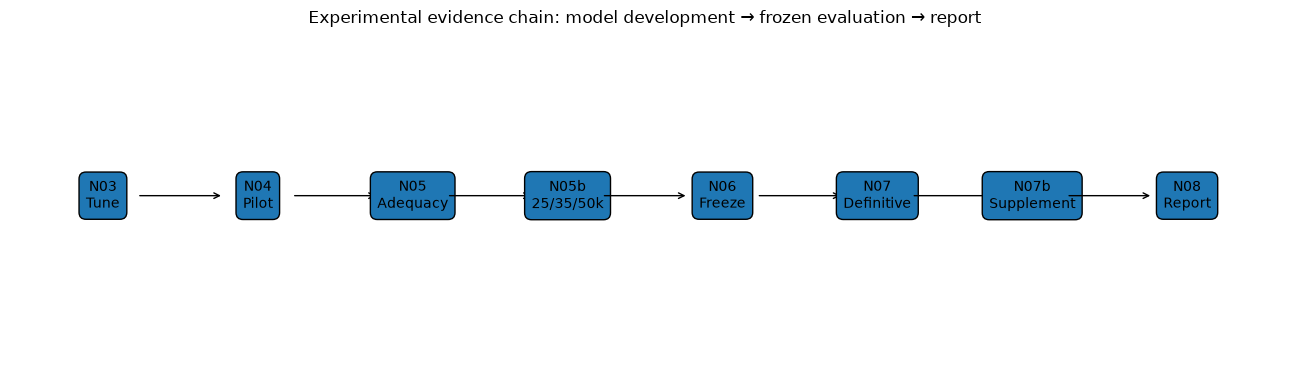

Saved: /home/leeming/projects/deep-learning-vla-robustness/results/figures/final_assignment_evidence/report_experimental_pipeline.png


In [6]:
fig, ax = plt.subplots(
    figsize=(13, 3.8)
)

ax.axis("off")

labels = [
    "N03\nTune",
    "N04\nPilot",
    "N05\nAdequacy",
    "N05b\n25/35/50k",
    "N06\nFreeze",
    "N07\nDefinitive",
    "N07b\nSupplement",
    "N08\nReport",
]

for i, label in enumerate(labels):
    ax.text(
        i,
        0.5,
        label,
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.5"
        ),
    )

    if i < len(labels) - 1:
        ax.annotate(
            "",
            xy=(i + 0.78, 0.5),
            xytext=(i + 0.22, 0.5),
            arrowprops=dict(
                arrowstyle="->"
            ),
        )

ax.set_xlim(
    -0.6,
    len(labels) - 0.4,
)
ax.set_ylim(
    0,
    1,
)
ax.set_title(
    "Experimental evidence chain: "
    "model development → frozen evaluation → report"
)

fig.tight_layout()

pipeline_figure_path = (
    REPORT_FIGURES_DIR
    / "report_experimental_pipeline.png"
)

fig.savefig(
    pipeline_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    pipeline_figure_path,
)

## 5. Hyperparameter tuning evidence

Optimizer selection was performed on **M1 only** and then frozen for the robustness variants. This avoids tuning the proposed model directly against final OOD outcomes.

In [7]:
tuning_df = (
    pd.read_csv(
        ARTIFACTS[
            "n03_tuning"
        ]
    )
    .sort_values(
        "validation_loss"
    )
    .reset_index(
        drop=True
    )
)

optimizer_cfg = read_json(
    ARTIFACTS[
        "n03_optimizer"
    ]
)

required_tuning_cols = {
    "tuning_id",
    "learning_rate",
    "weight_decay",
    "validation_loss",
}

assert required_tuning_cols.issubset(
    tuning_df.columns
)

assert len(
    tuning_df
) == 6

assert (
    str(
        optimizer_cfg[
            "selected_tuning_id"
        ]
    )
    == str(
        tuning_df.iloc[0][
            "tuning_id"
        ]
    )
)

tuning_report_df = (
    tuning_df[
        [
            "tuning_id",
            "learning_rate",
            "weight_decay",
            "validation_loss",
            "final_logged_train_loss",
            "training_seconds",
            "peak_logged_gpu_memory_gb",
        ]
    ]
    .copy()
)

display(
    tuning_report_df
)

display(
    pd.DataFrame(
        [optimizer_cfg]
    ).T.rename(
        columns={
            0: "Selected value"
        }
    )
)

tuning_report_df.to_csv(
    REPORT_METRICS_DIR
    / "report_tuning_summary.csv",
    index=False,
)

print(
    "HYPERPARAMETER TUNING EVIDENCE: PASS"
)

,tuning_id,learning_rate,weight_decay,validation_loss,final_logged_train_loss,training_seconds,peak_logged_gpu_memory_gb
0,T06,0.00010,0.01,0.976153,0.971967,28.733372,2.104808
1,T05,0.00010,0.00,0.976167,0.971921,30.375474,2.096794
2,T03,0.00003,0.00,1.146196,1.131429,30.729941,2.095502
3,T04,0.00003,0.01,1.146229,1.131530,31.245272,2.096794
4,T02,0.00001,0.01,1.469019,1.557492,29.063683,2.095502
5,T01,0.00001,0.00,1.469139,1.558522,28.649859,2.095502


,Selected value
selected_tuning_id,T06
learning_rate,0.0001
weight_decay,0.01
validation_loss,0.976153
tuning_seed,42
selection_rule,Minimum mean loss on frozen validation subset


HYPERPARAMETER TUNING EVIDENCE: PASS


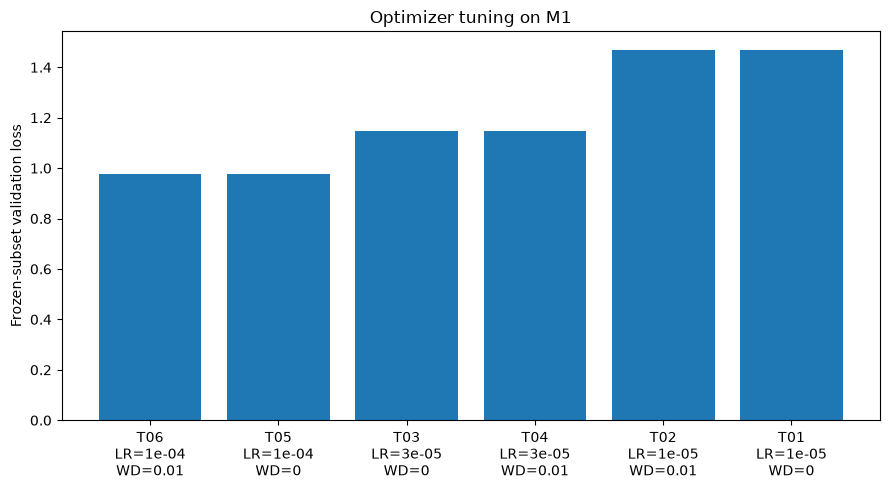

In [8]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

labels = [
    (
        f"{row.tuning_id}\n"
        f"LR={row.learning_rate:.0e}\n"
        f"WD={row.weight_decay:g}"
    )
    for row
    in tuning_report_df.itertuples()
]

ax.bar(
    np.arange(
        len(
            tuning_report_df
        )
    ),
    tuning_report_df[
        "validation_loss"
    ],
)

ax.set_xticks(
    np.arange(
        len(
            labels
        )
    )
)

ax.set_xticklabels(
    labels
)

ax.set_ylabel(
    "Frozen-subset validation loss"
)

ax.set_title(
    "Optimizer tuning on M1"
)

fig.tight_layout()

tuning_figure_path = (
    REPORT_FIGURES_DIR
    / "report_hyperparameter_tuning.png"
)

fig.savefig(
    tuning_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 6. Training-budget validation and the 25k freeze

The report must **not** say that 25k was globally optimal.

The defensible statement is:

> The final training budget was empirically frozen at 25,000 optimizer steps using a bounded, predeclared, multi-seed extension study. Neither 35k nor 50k satisfied every criterion required to replace the already-established 25k budget.

Selection used **E0 only**. Final OOD evidence remained unobserved during budget selection.

In [9]:
budget_df = (
    pd.read_csv(
        ARTIFACTS[
            "n05b_budget"
        ]
    )
    .sort_values(
        "training_steps"
    )
    .reset_index(
        drop=True
    )
)

replacement_df = pd.read_csv(
    ARTIFACTS[
        "n05b_replacement"
    ]
)

display(
    budget_df
)
display(
    replacement_df
)

assert int(
    n05b_handoff[
        "final_training_steps"
    ]
) == 25000

assert bool(
    n05b_handoff[
        "final_budget_frozen"
    ]
)

assert (
    n05b_handoff[
        "budget_selection_used_ood_results"
    ]
    is False
)

budget_report_df = (
    budget_df.copy()
)

budget_report_df[
    "frozen_final_budget"
] = (
    budget_report_df[
        "training_steps"
    ].astype(int)
    == 25000
)

budget_report_df.to_csv(
    REPORT_METRICS_DIR
    / "report_budget_selection_summary.csv",
    index=False,
)

if ARTIFACTS[
    "n05b_repro"
].exists():
    reproduction_df = pd.read_csv(
        ARTIFACTS[
            "n05b_repro"
        ]
    )

    display(
        reproduction_df.T
    )

print(
    "TRAINING-BUDGET EVIDENCE: PASS"
)

,training_steps,seed_count,mean_seed_success_rate,sd_across_seeds,pooled_success_rate,total_successes,total_episodes,mean_validation_loss,sd_validation_loss,selected_final_budget
0,25000,3,0.473333,0.102632,0.473333,71,150,0.553240,0.013054,True
1,35000,3,0.486667,0.098658,0.486667,73,150,0.552792,0.009840,False
2,50000,3,0.533333,0.075719,0.533333,80,150,0.561534,0.008261,False


,comparison_steps,mean_seed_success_rate,delta_vs_25k_pp,bootstrap_95_lower_pp,bootstrap_95_upper_pp,holm_adjusted_p_value,improved_seeds,adequate,practical_gain,ci_positive,paired_significant,seed_consistent,qualifies_to_replace_25k
0,35000,0.486667,1.333333,-19.333333,25.333333,0.895683,1,False,False,False,False,False,False
1,50000,0.533333,6.000000,-13.333333,27.333333,0.642168,1,True,True,False,False,False,False


,0
Notebook 05 25k seed-42 success,0.633333
Notebook 05b 25k seed-42 reproduction,0.5
Difference (percentage points),-13.333333
Notebook 05 adequacy threshold,0.533333
Diagnostic status,VARIABILITY OBSERVED


TRAINING-BUDGET EVIDENCE: PASS


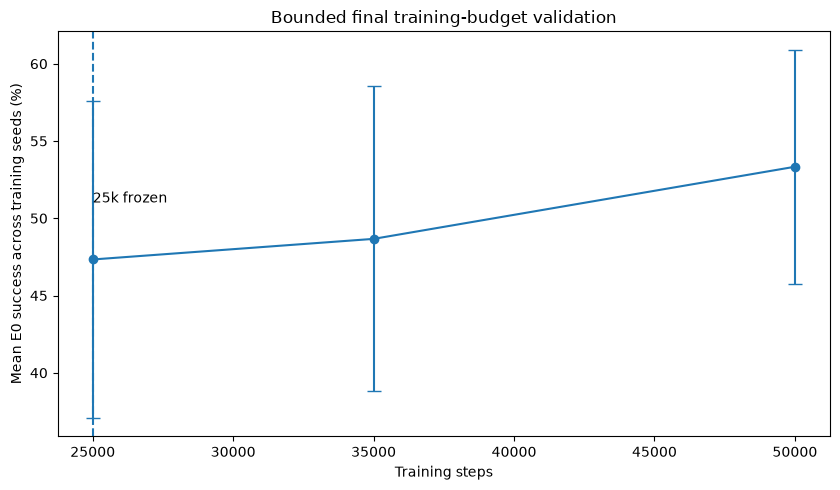

In [10]:
fig, ax = plt.subplots(
    figsize=(8.5, 5)
)

plot_df = budget_df.sort_values(
    "training_steps"
)

x = (
    plot_df[
        "training_steps"
    ]
    .to_numpy()
)

y = (
    plot_df[
        "mean_seed_success_rate"
    ]
    .to_numpy()
    * 100.0
)

yerr = (
    plot_df[
        "sd_across_seeds"
    ]
    .fillna(0)
    .to_numpy()
    * 100.0
)

ax.errorbar(
    x,
    y,
    yerr=yerr,
    marker="o",
    capsize=5,
)

ax.axvline(
    25000,
    linestyle="--",
)

ax.text(
    25000,
    max(y) * 0.97,
    "25k frozen",
    ha="left",
    va="top",
)

ax.set_xlabel(
    "Training steps"
)

ax.set_ylabel(
    "Mean E0 success across training seeds (%)"
)

ax.set_title(
    "Bounded final training-budget validation"
)

fig.tight_layout()

budget_figure_path = (
    REPORT_FIGURES_DIR
    / "report_training_budget_validation.png"
)

fig.savefig(
    budget_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 7. Final frozen model registry

The headline comparison is **M1 vs M2-LE across three matched training seeds**.

M2-L and M2-E are **single-seed mechanism ablations**, not multi-seed headline competitors.

In [11]:
registry_df = pd.read_csv(
    ARTIFACTS[
        "n06_registry"
    ]
)

required_registry_cols = {
    "variant",
    "seed",
    "role",
    "training_steps",
    "validation_loss",
    "checkpoint",
    "source_notebook",
}

assert required_registry_cols.issubset(
    registry_df.columns
)

assert len(
    registry_df
) == 8

assert (
    registry_df[
        "training_steps"
    ].astype(int)
    == 25000
).all()

registry_report_df = (
    registry_df[
        [
            "variant",
            "seed",
            "role",
            "training_steps",
            "validation_loss",
            "source_notebook",
        ]
    ]
    .sort_values(
        [
            "variant",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    registry_report_df
)

registry_report_df.to_csv(
    REPORT_METRICS_DIR
    / "report_final_model_registry.csv",
    index=False,
)

variant_validation_df = (
    registry_df
    .groupby(
        "variant",
        as_index=False,
    )
    .agg(
        model_count=(
            "seed",
            "count",
        ),
        mean_validation_loss=(
            "validation_loss",
            "mean",
        ),
        sd_validation_loss=(
            "validation_loss",
            "std",
        ),
    )
)

display(
    variant_validation_df
)

print(
    "FINAL MODEL REGISTRY: PASS"
)

,variant,seed,role,training_steps,validation_loss,source_notebook
0,M1,42,primary_control,25000,0.570412,05b
1,M1,123,primary_control,25000,0.564678,05b
2,M1,2026,primary_control,25000,0.557629,05b
3,M2-E,42,ablation,25000,0.556888,06
4,M2-L,42,ablation,25000,0.589158,06
5,M2-LE,42,primary_proposed,25000,0.581579,06
6,M2-LE,123,primary_proposed,25000,0.557852,06
7,M2-LE,2026,primary_proposed,25000,0.578886,06


,variant,model_count,mean_validation_loss,sd_validation_loss
0,M1,3,0.564239,0.006403
1,M2-E,1,0.556888,NaN
2,M2-L,1,0.589158,NaN
3,M2-LE,3,0.572773,0.012991


FINAL MODEL REGISTRY: PASS


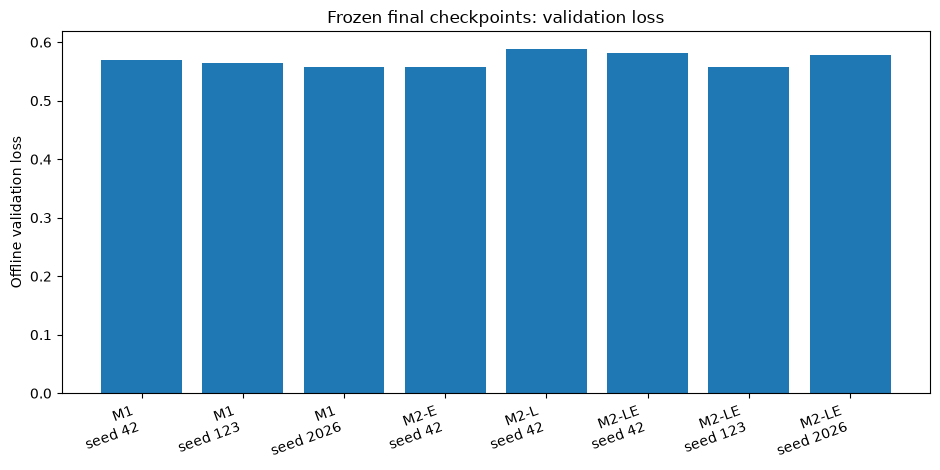

In [12]:
fig, ax = plt.subplots(
    figsize=(9.5, 4.8)
)

plot_registry = (
    registry_df
    .sort_values(
        [
            "variant",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)

labels = [
    (
        f"{row.variant}\n"
        f"seed {int(row.seed)}"
    )
    for row
    in plot_registry.itertuples()
]

ax.bar(
    np.arange(
        len(
            plot_registry
        )
    ),
    plot_registry[
        "validation_loss"
    ],
)

ax.set_xticks(
    np.arange(
        len(
            labels
        )
    )
)

ax.set_xticklabels(
    labels,
    rotation=20,
    ha="right",
)

ax.set_ylabel(
    "Offline validation loss"
)

ax.set_title(
    "Frozen final checkpoints: validation loss"
)

fig.tight_layout()

validation_figure_path = (
    REPORT_FIGURES_DIR
    / "report_final_checkpoint_validation_loss.png"
)

fig.savefig(
    validation_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 8. Definitive E0–E4 headline results

These are the **primary / confirmatory** results from Notebook 07.

E5 is deliberately excluded from this table and appears later under its own supplementary heading.

In [13]:
headline_df = pd.read_csv(
    ARTIFACTS[
        "n07_headline"
    ]
)

required_headline_cols = {
    "condition_id",
    "condition_label",
    "m1_mean_success",
    "m2le_mean_success",
    "paired_delta_pp",
    "paired_bootstrap_95_lower_pp",
    "paired_bootstrap_95_upper_pp",
    "holm_adjusted_mcnemar_p",
    "improved_seeds",
    "evidence_class",
}

assert required_headline_cols.issubset(
    headline_df.columns
)

assert len(
    headline_df
) == 5

headline_report_df = (
    headline_df.copy()
)

headline_report_df[
    "methodological_status"
] = (
    "PRIMARY_CONFIRMATORY"
)

display(
    headline_report_df[
        [
            "condition_id",
            "condition_label",
            "m1_mean_success",
            "m2le_mean_success",
            "paired_delta_pp",
            "paired_bootstrap_95_lower_pp",
            "paired_bootstrap_95_upper_pp",
            "holm_adjusted_mcnemar_p",
            "improved_seeds",
            "evidence_class",
        ]
    ]
)

headline_report_df.to_csv(
    REPORT_METRICS_DIR
    / "report_definitive_headline_results.csv",
    index=False,
)

print(
    "DEFINITIVE HEADLINE RESULTS: PASS"
)

,condition_id,condition_label,m1_mean_success,m2le_mean_success,paired_delta_pp,paired_bootstrap_95_lower_pp,paired_bootstrap_95_upper_pp,holm_adjusted_mcnemar_p,improved_seeds,evidence_class
0,E0_ID,ID / L0,0.513333,0.446667,-6.666667,-26.666667,14.000000,2.593117e-01,1,DIRECTIONAL_EVIDENCE_AGAINST
1,E1_L3,Language L3 held-out,0.060000,0.326667,26.666667,14.666667,38.666667,7.569163e-09,3,STRONG_MULTI_SEED_SUPPORT
2,E2_SEEN_PHOTO,Seen photometric shift,0.593333,0.493333,-10.000000,-25.333333,6.000000,2.593117e-01,0,DIRECTIONAL_EVIDENCE_AGAINST
3,E3_HELDOUT_NOISE,Held-out sensor noise,0.480000,0.580000,10.000000,-4.666667,24.666667,2.593117e-01,3,DIRECTIONAL_SUPPORT
4,E4_COMBINED,L3 + photometric,0.093333,0.266667,17.333333,2.000000,32.666667,6.256688e-04,3,STRONG_MULTI_SEED_SUPPORT


DEFINITIVE HEADLINE RESULTS: PASS


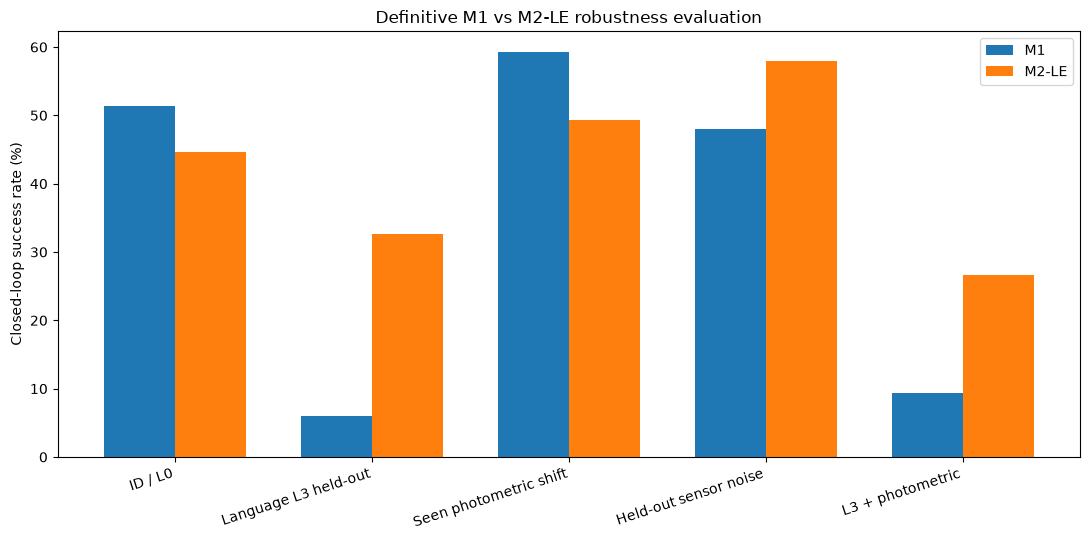

In [14]:
fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

x = np.arange(
    len(
        headline_df
    )
)

width = 0.36

ax.bar(
    x - width / 2,
    headline_df[
        "m1_mean_success"
    ] * 100.0,
    width,
    label="M1",
)

ax.bar(
    x + width / 2,
    headline_df[
        "m2le_mean_success"
    ] * 100.0,
    width,
    label="M2-LE",
)

ax.set_ylabel(
    "Closed-loop success rate (%)"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    headline_df[
        "condition_label"
    ],
    rotation=18,
    ha="right",
)

ax.set_title(
    "Definitive M1 vs M2-LE robustness evaluation"
)

ax.legend()

fig.tight_layout()

primary_figure_path = (
    REPORT_FIGURES_DIR
    / "report_primary_m1_vs_m2le.png"
)

fig.savefig(
    primary_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

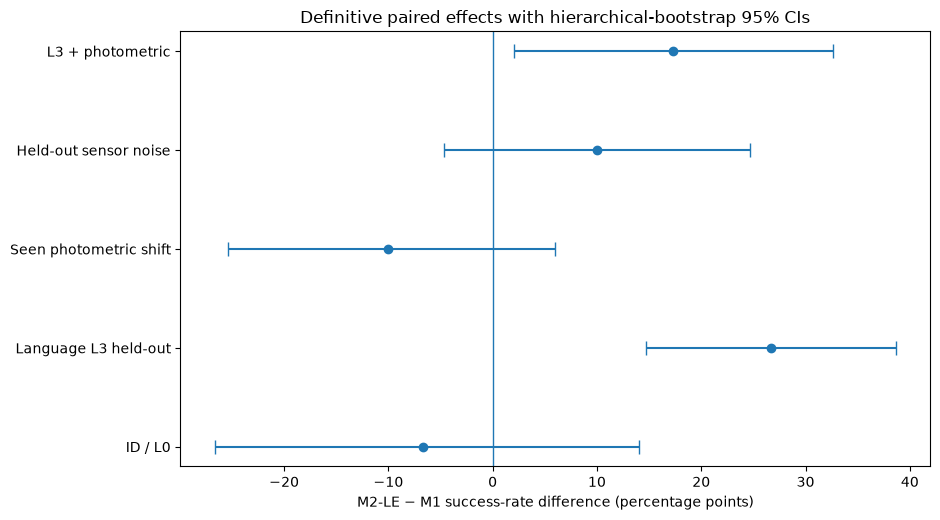

In [15]:
fig, ax = plt.subplots(
    figsize=(9.5, 5.3)
)

effect_plot = (
    headline_df.copy()
)

center = (
    effect_plot[
        "paired_delta_pp"
    ]
    .to_numpy()
)

lower = (
    effect_plot[
        "paired_bootstrap_95_lower_pp"
    ]
    .to_numpy()
)

upper = (
    effect_plot[
        "paired_bootstrap_95_upper_pp"
    ]
    .to_numpy()
)

xerr = np.vstack(
    [
        center - lower,
        upper - center,
    ]
)

y = np.arange(
    len(
        effect_plot
    )
)

ax.errorbar(
    center,
    y,
    xerr=xerr,
    fmt="o",
    capsize=5,
)

ax.axvline(
    0,
    linewidth=1,
)

ax.set_yticks(
    y
)

ax.set_yticklabels(
    effect_plot[
        "condition_label"
    ]
)

ax.set_xlabel(
    "M2-LE − M1 success-rate difference "
    "(percentage points)"
)

ax.set_title(
    "Definitive paired effects with "
    "hierarchical-bootstrap 95% CIs"
)

fig.tight_layout()

effect_figure_path = (
    REPORT_FIGURES_DIR
    / "report_primary_paired_effect_ci.png"
)

fig.savefig(
    effect_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 9. Mechanism ablations

The ablations answer a different question from the primary three-seed comparison.

- **M2-L** asks whether language augmentation explains the language-robustness pattern.
- **M2-E** asks whether the simple photometric augmentation independently improves visual robustness.
- **M2-LE** shows the combined intervention.

Because M2-L and M2-E were trained only at seed 42, they are **mechanism evidence**, not multi-seed confirmation.

In [16]:
language_df = pd.read_csv(
    ARTIFACTS[
        "n07_language"
    ]
)

environment_df = pd.read_csv(
    ARTIFACTS[
        "n07_environment"
    ]
)

language_show_cols = [
    col
    for col in [
        "variant",
        "condition_id",
        "successes",
        "episodes",
        "success_rate",
        "mean_steps",
    ]
    if col in language_df.columns
]

environment_show_cols = [
    col
    for col in [
        "variant",
        "condition_id",
        "successes",
        "episodes",
        "success_rate",
        "mean_steps",
    ]
    if col in environment_df.columns
]

display(
    language_df[
        language_show_cols
    ]
)

display(
    environment_df[
        environment_show_cols
    ]
)

print(
    "MECHANISM ABLATION TABLES: PASS"
)

,variant,condition_id,successes,episodes,success_rate,mean_steps
0,M1,E0_ID,31,50,0.62,174.24
1,M1,E1_L1,8,50,0.16,250.58
2,M1,E1_L2,7,50,0.14,253.72
3,M1,E1_L3,5,50,0.10,260.90
4,M2-L,E0_ID,26,50,0.52,189.36
5,M2-L,E1_L1,25,50,0.50,194.56
6,M2-L,E1_L2,26,50,0.52,187.68
7,M2-L,E1_L3,13,50,0.26,234.40
8,M2-LE,E0_ID,20,50,0.40,212.42
9,M2-LE,E1_L1,24,50,0.48,200.08


,variant,condition_id,successes,episodes,success_rate,mean_steps
0,M1,E0_ID,31,50,0.62,174.24
1,M1,E2_SEEN_PHOTO,30,50,0.60,179.16
2,M1,E3_HELDOUT_NOISE,27,50,0.54,185.60
3,M2-E,E0_ID,23,50,0.46,198.60
4,M2-E,E2_SEEN_PHOTO,28,50,0.56,186.54
5,M2-E,E3_HELDOUT_NOISE,27,50,0.54,185.08
6,M2-LE,E0_ID,20,50,0.40,212.42
7,M2-LE,E2_SEEN_PHOTO,23,50,0.46,203.30
8,M2-LE,E3_HELDOUT_NOISE,30,50,0.60,171.72


MECHANISM ABLATION TABLES: PASS


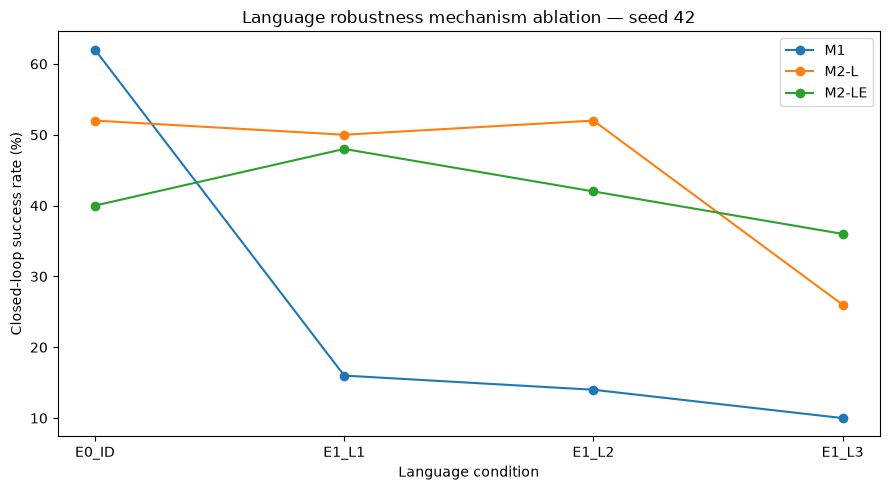

In [17]:
language_order = [
    "E0_ID",
    "E1_L1",
    "E1_L2",
    "E1_L3",
]

language_plot = (
    language_df.copy()
)

language_plot[
    "order"
] = (
    language_plot[
        "condition_id"
    ]
    .map(
        {
            key: i
            for i, key
            in enumerate(
                language_order
            )
        }
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

for variant in [
    "M1",
    "M2-L",
    "M2-LE",
]:
    data = (
        language_plot[
            language_plot[
                "variant"
            ]
            == variant
        ]
        .sort_values(
            "order"
        )
    )

    if not data.empty:
        ax.plot(
            data[
                "condition_id"
            ],
            data[
                "success_rate"
            ] * 100.0,
            marker="o",
            label=variant,
        )

ax.set_ylabel(
    "Closed-loop success rate (%)"
)
ax.set_xlabel(
    "Language condition"
)
ax.set_title(
    "Language robustness mechanism ablation — seed 42"
)
ax.legend()

fig.tight_layout()

language_figure_path = (
    REPORT_FIGURES_DIR
    / "report_language_ablation.png"
)

fig.savefig(
    language_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

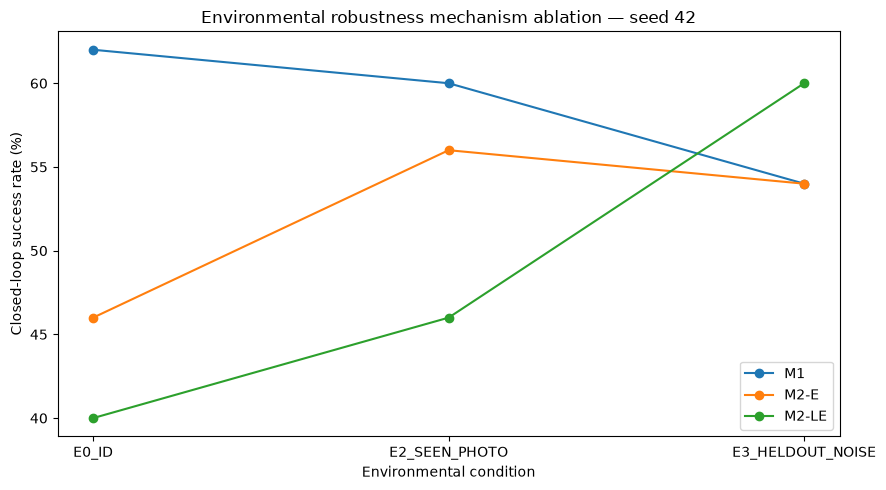

In [18]:
environment_order = [
    "E0_ID",
    "E2_SEEN_PHOTO",
    "E3_HELDOUT_NOISE",
]

environment_plot = (
    environment_df.copy()
)

environment_plot[
    "order"
] = (
    environment_plot[
        "condition_id"
    ]
    .map(
        {
            key: i
            for i, key
            in enumerate(
                environment_order
            )
        }
    )
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

for variant in [
    "M1",
    "M2-E",
    "M2-LE",
]:
    data = (
        environment_plot[
            environment_plot[
                "variant"
            ]
            == variant
        ]
        .sort_values(
            "order"
        )
    )

    if not data.empty:
        ax.plot(
            data[
                "condition_id"
            ],
            data[
                "success_rate"
            ] * 100.0,
            marker="o",
            label=variant,
        )

ax.set_ylabel(
    "Closed-loop success rate (%)"
)
ax.set_xlabel(
    "Environmental condition"
)
ax.set_title(
    "Environmental robustness mechanism ablation — seed 42"
)
ax.legend()

fig.tight_layout()

environment_figure_path = (
    REPORT_FIGURES_DIR
    / "report_environment_ablation.png"
)

fig.savefig(
    environment_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 10. Supplementary E5 double-held-out stress test

E5 was added **after** the definitive Notebook 07 outcomes were known.

Therefore:

- it is scientifically useful;
- it can strengthen or challenge the interpretation;
- it **cannot** be retroactively promoted into the original confirmatory family;
- its raw McNemar p-value remains separate from Notebook 07's Holm correction.

In [19]:
e5_context_df = pd.read_csv(
    ARTIFACTS[
        "n07b_context"
    ]
)

e5_effect_df = pd.read_csv(
    ARTIFACTS[
        "n07b_effect"
    ]
)

assert len(
    e5_effect_df
) == 1

assert (
    str(
        e5_effect_df.iloc[0][
            "methodological_status"
        ]
    )
    == "SUPPLEMENTARY_EXPLORATORY"
)

display(
    e5_context_df
)

display(
    e5_effect_df
)

e5_context_df.to_csv(
    REPORT_METRICS_DIR
    / "report_confirmatory_plus_e5_context.csv",
    index=False,
)

print(
    "SUPPLEMENTARY E5 EVIDENCE: PASS"
)

,condition_id,condition_label,m1_mean_success,m2le_mean_success,paired_delta_pp,paired_bootstrap_95_lower_pp,paired_bootstrap_95_upper_pp,evidence_class
0,E0_ID,ID / L0,0.513333,0.446667,-6.666667,-26.666667,14.000000,DIRECTIONAL_EVIDENCE_AGAINST
1,E1_L3,Language L3 held-out,0.060000,0.326667,26.666667,14.666667,38.666667,STRONG_MULTI_SEED_SUPPORT
2,E3_HELDOUT_NOISE,Held-out sensor noise,0.480000,0.580000,10.000000,-4.666667,24.666667,DIRECTIONAL_SUPPORT
3,E4_COMBINED,L3 + photometric,0.093333,0.266667,17.333333,2.000000,32.666667,STRONG_MULTI_SEED_SUPPORT
4,E5_DOUBLE_HELDOUT,L3 + held-out Gaussian noise (exploratory),0.046667,0.213333,16.666667,4.666667,31.333333,EXPLORATORY_STRONG_SUPPORT


,condition_id,paired_episodes,observed_delta,observed_delta_pp,bootstrap_95_lower,bootstrap_95_upper,bootstrap_95_lower_pp,bootstrap_95_upper_pp,improved_seeds,tied_seeds,worsened_seeds,mean_seed_delta,sd_seed_delta,raw_exact_mcnemar_p,evidence_class,methodological_status
0,E5_DOUBLE_HELDOUT,150,0.166667,16.666667,0.046667,0.313333,4.666667,31.333333,3,0,0,0.166667,0.102632,0.000011,EXPLORATORY_STRONG_SUPPORT,SUPPLEMENTARY_EXPLORATORY


SUPPLEMENTARY E5 EVIDENCE: PASS


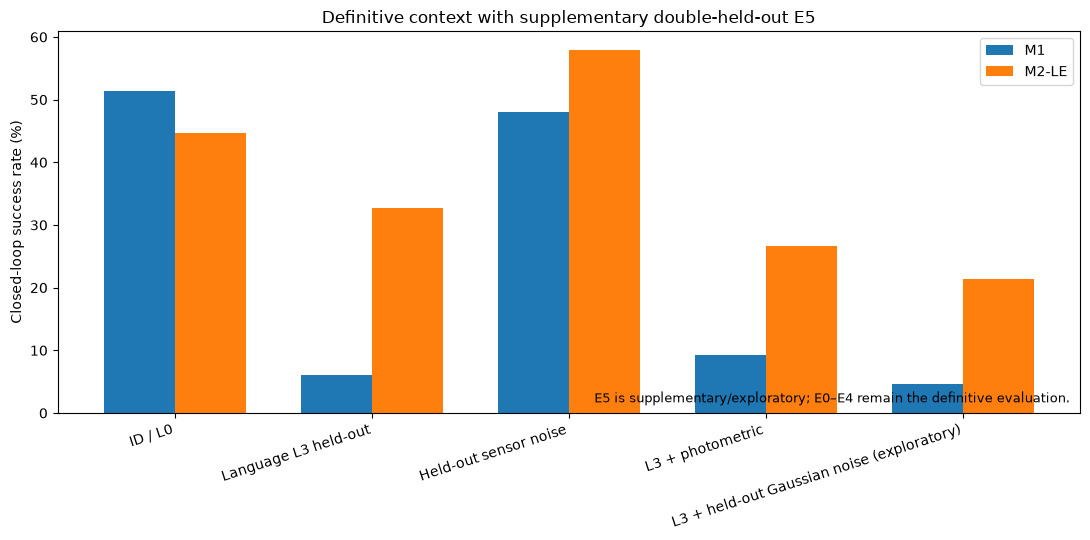

In [20]:
fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

x = np.arange(
    len(
        e5_context_df
    )
)

width = 0.36

ax.bar(
    x - width / 2,
    e5_context_df[
        "m1_mean_success"
    ] * 100.0,
    width,
    label="M1",
)

ax.bar(
    x + width / 2,
    e5_context_df[
        "m2le_mean_success"
    ] * 100.0,
    width,
    label="M2-LE",
)

ax.set_ylabel(
    "Closed-loop success rate (%)"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    e5_context_df[
        "condition_label"
    ],
    rotation=18,
    ha="right",
)

ax.set_title(
    "Definitive context with supplementary double-held-out E5"
)

ax.legend()

ax.text(
    0.99,
    0.02,
    (
        "E5 is supplementary/exploratory; "
        "E0–E4 remain the definitive evaluation."
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

e5_figure_path = (
    REPORT_FIGURES_DIR
    / "report_e5_context.png"
)

fig.savefig(
    e5_figure_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 11. Research-question evidence

Notebook 07 remains the authoritative source for RQ1–RQ5.

E5 is appended only as **supplementary evidence**, especially for the interpretation of RQ4. It does not replace Notebook 07's original evidence classification.

In [21]:
rq_source_df = pd.read_csv(
    ARTIFACTS[
        "n07_rq"
    ]
)

assert len(
    rq_source_df
) == 5

display(
    rq_source_df
)

e5_row = (
    e5_effect_df.iloc[0]
)

rq_report_df = (
    rq_source_df.copy()
)

if (
    "supplementary_e5_note"
    not in rq_report_df.columns
):
    rq_report_df[
        "supplementary_e5_note"
    ] = ""

rq_report_df.loc[
    rq_report_df[
        "research_question"
    ]
    == "RQ4",
    "supplementary_e5_note",
] = (
    "Supplementary E5 composed held-out L3 language "
    "with held-out Gaussian noise. "
    f"M2-LE−M1={float(e5_row['observed_delta_pp']):.1f} pp, "
    f"95% hierarchical-bootstrap CI "
    f"[{float(e5_row['bootstrap_95_lower_pp']):.1f}, "
    f"{float(e5_row['bootstrap_95_upper_pp']):.1f}] pp; "
    f"{int(e5_row['improved_seeds'])}/3 seeds improved. "
    "This is exploratory evidence and does not alter "
    "the original confirmatory family."
)

display(
    rq_report_df
)

rq_report_df.to_csv(
    REPORT_METRICS_DIR
    / "report_research_question_answers.csv",
    index=False,
)

print(
    "RQ1–RQ5 EVIDENCE MAP: PASS"
)

,research_question,question,primary_evidence,evidence_class
0,RQ1,Does robustness-oriented fine-tuning improve c...,"M2-LE−M1 paired effects: L3=+26.7 pp, photo=-1...",STRONG_MULTI_SEED_SUPPORT/DIRECTIONAL_EVIDENCE...
1,RQ2,How does language variation affect SmolVLA and...,"Seed-42 L0/L1/L2/L3 curves compare M1, M2-L an...",STRONG_MULTI_SEED_SUPPORT
2,RQ3,Which evaluated environmental perturbations ca...,Primary generalization gaps quantify photometr...,DESCRIPTIVE_COMPARISON
3,RQ4,Does robustness training transfer to held-out ...,Held-out L3 effect=+26.7 pp; held-out noise ef...,L3:STRONG_MULTI_SEED_SUPPORT | NOISE:DIRECTION...
4,RQ5,Is robustness associated with an ID-performanc...,ID M2-LE−M1 paired effect=-6.7 pp; M1 mean ID=...,DIRECTIONAL_EVIDENCE_AGAINST


,research_question,question,primary_evidence,evidence_class,supplementary_e5_note
0,RQ1,Does robustness-oriented fine-tuning improve c...,"M2-LE−M1 paired effects: L3=+26.7 pp, photo=-1...",STRONG_MULTI_SEED_SUPPORT/DIRECTIONAL_EVIDENCE...,
1,RQ2,How does language variation affect SmolVLA and...,"Seed-42 L0/L1/L2/L3 curves compare M1, M2-L an...",STRONG_MULTI_SEED_SUPPORT,
2,RQ3,Which evaluated environmental perturbations ca...,Primary generalization gaps quantify photometr...,DESCRIPTIVE_COMPARISON,
3,RQ4,Does robustness training transfer to held-out ...,Held-out L3 effect=+26.7 pp; held-out noise ef...,L3:STRONG_MULTI_SEED_SUPPORT | NOISE:DIRECTION...,Supplementary E5 composed held-out L3 language...
4,RQ5,Is robustness associated with an ID-performanc...,ID M2-LE−M1 paired effect=-6.7 pp; M1 mean ID=...,DIRECTIONAL_EVIDENCE_AGAINST,


RQ1–RQ5 EVIDENCE MAP: PASS


## 12. Critical-analysis claim ledger

This table separates **what the evidence supports** from tempting but unjustified claims.

It is designed to feed directly into the report-writing stage.

In [22]:
def headline_row(
    condition_id
):
    return (
        headline_df.loc[
            headline_df[
                "condition_id"
            ]
            == condition_id
        ]
        .iloc[0]
    )


id_result = headline_row(
    "E0_ID"
)
l3_result = headline_row(
    "E1_L3"
)
photo_result = headline_row(
    "E2_SEEN_PHOTO"
)
noise_result = headline_row(
    "E3_HELDOUT_NOISE"
)
combined_result = headline_row(
    "E4_COMBINED"
)
e5_result = e5_effect_df.iloc[0]


claim_rows = [
    {
        "finding":
            "Held-out language robustness",

        "evidence":
            (
                f"M2-LE−M1="
                f"{l3_result['paired_delta_pp']:.1f} pp; "
                f"95% CI "
                f"[{l3_result['paired_bootstrap_95_lower_pp']:.1f}, "
                f"{l3_result['paired_bootstrap_95_upper_pp']:.1f}] pp; "
                f"{l3_result['evidence_class']}"
            ),

        "allowed_report_wording":
            (
                "Combined robustness-oriented fine-tuning produced "
                "strong multi-seed support for improved generalization "
                "to held-out L3 language."
            ),

        "do_not_claim":
            (
                "Universal language understanding or robustness "
                "to arbitrary instructions."
            ),
    },

    {
        "finding":
            "Seen-family photometric robustness",

        "evidence":
            (
                f"M2-LE−M1="
                f"{photo_result['paired_delta_pp']:.1f} pp; "
                f"95% CI "
                f"[{photo_result['paired_bootstrap_95_lower_pp']:.1f}, "
                f"{photo_result['paired_bootstrap_95_upper_pp']:.1f}] pp; "
                f"{photo_result['evidence_class']}"
            ),

        "allowed_report_wording":
            (
                "The simple photometric augmentation did not produce "
                "a corresponding advantage under the evaluated "
                "seen-family photometric shift."
            ),

        "do_not_claim":
            (
                "Photometric augmentation is generally harmful."
            ),
    },

    {
        "finding":
            "Held-out sensor-noise transfer",

        "evidence":
            (
                f"M2-LE−M1="
                f"{noise_result['paired_delta_pp']:.1f} pp; "
                f"95% CI "
                f"[{noise_result['paired_bootstrap_95_lower_pp']:.1f}, "
                f"{noise_result['paired_bootstrap_95_upper_pp']:.1f}] pp; "
                f"{noise_result['evidence_class']}"
            ),

        "allowed_report_wording":
            (
                "Held-out Gaussian noise showed positive and "
                "seed-consistent directional evidence, but the "
                "confirmatory uncertainty interval crossed zero."
            ),

        "do_not_claim":
            (
                "Statistically confirmed universal visual OOD robustness."
            ),
    },

    {
        "finding":
            "Combined L3 + seen photometric shift",

        "evidence":
            (
                f"M2-LE−M1="
                f"{combined_result['paired_delta_pp']:.1f} pp; "
                f"95% CI "
                f"[{combined_result['paired_bootstrap_95_lower_pp']:.1f}, "
                f"{combined_result['paired_bootstrap_95_upper_pp']:.1f}] pp; "
                f"{combined_result['evidence_class']}"
            ),

        "allowed_report_wording":
            (
                "The robustness advantage persisted under the "
                "predeclared combined language-plus-photometric condition."
            ),

        "do_not_claim":
            (
                "General robustness to all simultaneous real-world shifts."
            ),
    },

    {
        "finding":
            "Supplementary double-held-out E5",

        "evidence":
            (
                f"M2-LE−M1="
                f"{e5_result['observed_delta_pp']:.1f} pp; "
                f"95% CI "
                f"[{e5_result['bootstrap_95_lower_pp']:.1f}, "
                f"{e5_result['bootstrap_95_upper_pp']:.1f}] pp; "
                f"{e5_result['evidence_class']}"
            ),

        "allowed_report_wording":
            (
                "A post-hoc supplementary stress test provided "
                "strong exploratory evidence that the advantage "
                "persisted when held-out language and held-out "
                "Gaussian noise were composed."
            ),

        "do_not_claim":
            (
                "E5 was preregistered or belongs to the original "
                "Holm-corrected confirmatory family."
            ),
    },

    {
        "finding":
            "Possible ID trade-off",

        "evidence":
            (
                f"M2-LE−M1="
                f"{id_result['paired_delta_pp']:.1f} pp; "
                f"95% CI "
                f"[{id_result['paired_bootstrap_95_lower_pp']:.1f}, "
                f"{id_result['paired_bootstrap_95_upper_pp']:.1f}] pp; "
                f"{id_result['evidence_class']}"
            ),

        "allowed_report_wording":
            (
                "A possible ID-performance trade-off was observed, "
                "but it was not statistically conclusive under the "
                "confirmatory analysis."
            ),

        "do_not_claim":
            (
                "Robustness training definitively reduces ID performance."
            ),
    },
]


claim_ledger_df = pd.DataFrame(
    claim_rows
)

display(
    claim_ledger_df
)

claim_ledger_df.to_csv(
    REPORT_METRICS_DIR
    / "report_critical_analysis_claims.csv",
    index=False,
)

print(
    "CRITICAL-ANALYSIS CLAIM LEDGER: PASS"
)

,finding,evidence,allowed_report_wording,do_not_claim
0,Held-out language robustness,"M2-LE−M1=26.7 pp; 95% CI [14.7, 38.7] pp; STRO...",Combined robustness-oriented fine-tuning produ...,Universal language understanding or robustness...
1,Seen-family photometric robustness,"M2-LE−M1=-10.0 pp; 95% CI [-25.3, 6.0] pp; DIR...",The simple photometric augmentation did not pr...,Photometric augmentation is generally harmful.
2,Held-out sensor-noise transfer,"M2-LE−M1=10.0 pp; 95% CI [-4.7, 24.7] pp; DIRE...",Held-out Gaussian noise showed positive and se...,Statistically confirmed universal visual OOD r...
3,Combined L3 + seen photometric shift,"M2-LE−M1=17.3 pp; 95% CI [2.0, 32.7] pp; STRON...",The robustness advantage persisted under the p...,General robustness to all simultaneous real-wo...
4,Supplementary double-held-out E5,"M2-LE−M1=16.7 pp; 95% CI [4.7, 31.3] pp; EXPLO...",A post-hoc supplementary stress test provided ...,E5 was preregistered or belongs to the origina...
5,Possible ID trade-off,"M2-LE−M1=-6.7 pp; 95% CI [-26.7, 14.0] pp; DIR...",A possible ID-performance trade-off was observ...,Robustness training definitively reduces ID pe...


CRITICAL-ANALYSIS CLAIM LEDGER: PASS


## 13. Limitations and threats to validity

A strong MSc report should state these directly rather than leaving the marker to infer them.

In [23]:
limitations_df = pd.DataFrame(
    [
        {
            "limitation":
                "Benchmark scope",

            "threat":
                (
                    "The implemented study does not evaluate "
                    "the full LIBERO-Plus suite."
                ),

            "implication":
                (
                    "Claims are restricted to the implemented "
                    "LIBERO-Spatial tasks and language/"
                    "photometric/noise conditions."
                ),

            "future_work":
                (
                    "Evaluate camera viewpoint, object-layout "
                    "and robot-initial-state shifts."
                ),
        },

        {
            "limitation":
                "Visual robustness mechanism",

            "threat":
                (
                    "Training-side environmental augmentation "
                    "is limited to brightness, contrast and saturation."
                ),

            "implication":
                (
                    "Mixed visual results should not be generalized "
                    "to all environmental-augmentation strategies."
                ),

            "future_work":
                (
                    "Investigate geometry-aware, sensor-aware "
                    "and broader corruption training."
                ),
        },

        {
            "limitation":
                "Single-seed component ablations",

            "threat":
                (
                    "M2-L and M2-E are mechanism ablations "
                    "at seed 42 only."
                ),

            "implication":
                (
                    "They explain mechanisms but do not provide "
                    "multi-seed confirmation."
                ),

            "future_work":
                (
                    "Replicate component ablations across more "
                    "training seeds in a future study."
                ),
        },

        {
            "limitation":
                "Training stochasticity",

            "threat":
                (
                    "Success varies materially across independent "
                    "optimization seeds."
                ),

            "implication":
                (
                    "Single-run conclusions would overstate certainty."
                ),

            "future_work":
                (
                    "Use larger seed counts and hierarchical "
                    "uncertainty in future work."
                ),
        },

        {
            "limitation":
                "Failure taxonomy",

            "threat":
                (
                    "Automated failure labels are proxies rather "
                    "than full semantic trajectory diagnoses."
                ),

            "implication":
                (
                    "Failure-type conclusions require curated "
                    "trajectory/video inspection."
                ),

            "future_work":
                (
                    "Perform manual semantic failure annotation "
                    "on representative successful/failed episodes."
                ),
        },

        {
            "limitation":
                "Simulation-only evidence",

            "threat":
                (
                    "The study establishes simulator robustness, "
                    "not physical-robot reliability."
                ),

            "implication":
                (
                    "No direct sim-to-real claim is justified."
                ),

            "future_work":
                (
                    "Validate the robustness pattern on a physical "
                    "manipulation platform."
                ),
        },

        {
            "limitation":
                "E5 post-hoc status",

            "threat":
                (
                    "E5 was motivated after definitive E0–E4 "
                    "outcomes were observed."
                ),

            "implication":
                (
                    "E5 is supplementary exploratory evidence "
                    "rather than confirmatory evidence."
                ),

            "future_work":
                (
                    "Predeclare double-held-out conditions in "
                    "an independent future replication."
                ),
        },
    ]
)

display(
    limitations_df
)

limitations_df.to_csv(
    REPORT_METRICS_DIR
    / "report_limitations_and_threats.csv",
    index=False,
)

print(
    "LIMITATIONS / THREATS TABLE: PASS"
)

,limitation,threat,implication,future_work
0,Benchmark scope,The implemented study does not evaluate the fu...,Claims are restricted to the implemented LIBER...,"Evaluate camera viewpoint, object-layout and r..."
1,Visual robustness mechanism,Training-side environmental augmentation is li...,Mixed visual results should not be generalized...,"Investigate geometry-aware, sensor-aware and b..."
2,Single-seed component ablations,M2-L and M2-E are mechanism ablations at seed ...,They explain mechanisms but do not provide mul...,Replicate component ablations across more trai...
3,Training stochasticity,Success varies materially across independent o...,Single-run conclusions would overstate certainty.,Use larger seed counts and hierarchical uncert...
4,Failure taxonomy,Automated failure labels are proxies rather th...,Failure-type conclusions require curated traje...,Perform manual semantic failure annotation on ...
5,Simulation-only evidence,"The study establishes simulator robustness, no...",No direct sim-to-real claim is justified.,Validate the robustness pattern on a physical ...
6,E5 post-hoc status,E5 was motivated after definitive E0–E4 outcom...,E5 is supplementary exploratory evidence rathe...,Predeclare double-held-out conditions in an in...


LIMITATIONS / THREATS TABLE: PASS


## 14. Assignment 2 rubric evidence map

The marking scheme allocates:

- **24 marks** — Model Implementation
- **18 marks** — Tuning and Validation
- **18 marks** — Visualization and Critical Analysis

Notebook 08 does not replace the implementation notebooks. It tells the marker exactly where the evidence lives.

In [24]:
rubric_df = pd.DataFrame(
    [
        {
            "rubric_component":
                "Model Implementation",

            "marks":
                24,

            "evidence":
                (
                    "Notebook 02 robustness-training implementation; "
                    "Notebook 03 custom training/evaluation path; "
                    "Notebook 06 frozen M1/M2-L/M2-E/M2-LE construction."
                ),

            "what_to_show_in_report":
                (
                    "SmolVLA architecture, trainable-scope decision, "
                    "language augmentation, photometric augmentation, "
                    "training loop and final-model registry."
                ),
        },

        {
            "rubric_component":
                "Tuning and Validation",

            "marks":
                18,

            "evidence":
                (
                    "Notebook 03 six-run optimizer tuning; "
                    "Notebook 05 evaluator/control and adequacy diagnosis; "
                    "Notebook 05b 25k/35k/50k multi-seed budget validation; "
                    "Notebook 06 final validation losses."
                ),

            "what_to_show_in_report":
                (
                    "Search space, frozen validation subset, selected optimizer, "
                    "floor-effect diagnosis, bounded budget criteria and "
                    "25k freeze rationale."
                ),
        },

        {
            "rubric_component":
                "Visualization and Critical Analysis",

            "marks":
                18,

            "evidence":
                (
                    "Notebook 07 2,050 definitive episodes with bootstrap, "
                    "McNemar/Holm, generalization gaps, ablations and failure analysis; "
                    "Notebook 07b 300-episode supplementary double-held-out test."
                ),

            "what_to_show_in_report":
                (
                    "Headline M1 vs M2-LE table, paired-effect CIs, "
                    "language/environment ablations, possible ID trade-off, "
                    "perturbation-specific findings, limitations and future work."
                ),
        },
    ]
)

display(
    rubric_df
)

rubric_df.to_csv(
    REPORT_METRICS_DIR
    / "assignment2_rubric_evidence_map.csv",
    index=False,
)

print(
    "ASSIGNMENT 2 RUBRIC MAP: PASS"
)

,rubric_component,marks,evidence,what_to_show_in_report
0,Model Implementation,24,Notebook 02 robustness-training implementation...,"SmolVLA architecture, trainable-scope decision..."
1,Tuning and Validation,18,Notebook 03 six-run optimizer tuning; Notebook...,"Search space, frozen validation subset, select..."
2,Visualization and Critical Analysis,18,"Notebook 07 2,050 definitive episodes with boo...","Headline M1 vs M2-LE table, paired-effect CIs,..."


ASSIGNMENT 2 RUBRIC MAP: PASS


## 15. Published-results comparison template

The assignment brief expects prior work on the **same problem/dataset** to be compared with the experimental results.

Notebook 08 intentionally does **not fabricate literature values**.

This empty template is created for the report-stage literature cross-check. Fill it only with numbers verified from the final academic sources.

In [25]:
published_template_path = (
    REPORT_METRICS_DIR
    / "published_results_comparison_template.csv"
)

published_columns = [
    "citation",
    "year",
    "model",
    "dataset_or_suite",
    "evaluation_condition",
    "metric",
    "published_value",
    "our_comparable_condition",
    "our_value",
    "directly_comparable",
    "comparison_notes",
    "doi_or_url",
]

if not published_template_path.exists():
    pd.DataFrame(
        columns=published_columns
    ).to_csv(
        published_template_path,
        index=False,
    )

published_template_df = pd.read_csv(
    published_template_path
)

display(
    published_template_df
)

print(
    "Published-results template saved. "
    "Populate only with values verified from the literature."
)

,citation,year,model,dataset_or_suite,evaluation_condition,metric,published_value,our_comparable_condition,our_value,directly_comparable,comparison_notes,doi_or_url


Published-results template saved. Populate only with values verified from the literature.


## 16. Report-ready narrative export

This creates a **results skeleton**, not final dissertation prose.

Its purpose is to make the final report reproducible: every numerical statement below comes from the saved experimental artifacts.

In [26]:
def pct(value):
    return (
        100.0
        * float(
            value
        )
    )


def row_by_condition(
    frame,
    condition_id,
):
    return (
        frame.loc[
            frame[
                "condition_id"
            ]
            == condition_id
        ]
        .iloc[0]
    )


e0 = row_by_condition(
    headline_df,
    "E0_ID",
)

e1 = row_by_condition(
    headline_df,
    "E1_L3",
)

e2 = row_by_condition(
    headline_df,
    "E2_SEEN_PHOTO",
)

e3 = row_by_condition(
    headline_df,
    "E3_HELDOUT_NOISE",
)

e4 = row_by_condition(
    headline_df,
    "E4_COMBINED",
)

e5 = (
    e5_effect_df.iloc[0]
)


narrative = f"""# Assignment 2 Results Evidence Skeleton

## Frozen model-development decisions

- Optimizer selected in Notebook 03: {optimizer_cfg['selected_tuning_id']}, learning rate {optimizer_cfg['learning_rate']}, weight decay {optimizer_cfg['weight_decay']}.
- Final training budget: {int(n05b_handoff['final_training_steps']):,} optimizer steps.
- Budget selection used E0 only; OOD results were not used for checkpoint selection.
- Final registry: 8 checkpoints, with M1 and M2-LE evaluated across seeds 42, 123 and 2026.
- No post-OOD retraining or model replacement was performed.

## Definitive / confirmatory findings — Notebook 07

- E0 ID: M1 {pct(e0['m1_mean_success']):.1f}% vs M2-LE {pct(e0['m2le_mean_success']):.1f}%; paired effect {e0['paired_delta_pp']:.1f} pp; {e0['evidence_class']}.
- E1 held-out L3: M1 {pct(e1['m1_mean_success']):.1f}% vs M2-LE {pct(e1['m2le_mean_success']):.1f}%; paired effect {e1['paired_delta_pp']:.1f} pp, 95% CI [{e1['paired_bootstrap_95_lower_pp']:.1f}, {e1['paired_bootstrap_95_upper_pp']:.1f}] pp; {e1['evidence_class']}.
- E2 seen photometric: M1 {pct(e2['m1_mean_success']):.1f}% vs M2-LE {pct(e2['m2le_mean_success']):.1f}%; paired effect {e2['paired_delta_pp']:.1f} pp; {e2['evidence_class']}.
- E3 held-out Gaussian noise: M1 {pct(e3['m1_mean_success']):.1f}% vs M2-LE {pct(e3['m2le_mean_success']):.1f}%; paired effect {e3['paired_delta_pp']:.1f} pp; {e3['evidence_class']}.
- E4 L3 + seen photometric: M1 {pct(e4['m1_mean_success']):.1f}% vs M2-LE {pct(e4['m2le_mean_success']):.1f}%; paired effect {e4['paired_delta_pp']:.1f} pp, 95% CI [{e4['paired_bootstrap_95_lower_pp']:.1f}, {e4['paired_bootstrap_95_upper_pp']:.1f}] pp; {e4['evidence_class']}.

## Supplementary / exploratory finding — Notebook 07b

- E5 L3 + held-out Gaussian noise: paired M2-LE−M1 effect {e5['observed_delta_pp']:.1f} pp, 95% CI [{e5['bootstrap_95_lower_pp']:.1f}, {e5['bootstrap_95_upper_pp']:.1f}] pp; {int(e5['improved_seeds'])}/3 training seeds improved; {e5['evidence_class']}.
- E5 was post-hoc supplementary evidence and was not part of Notebook 07's original Holm-corrected confirmatory family.

## Central interpretation

The strongest reproducible robustness benefit was linguistic generalization. The combined M2-LE intervention also retained a clear advantage under the predeclared L3+photometric condition and under the supplementary double-held-out L3+noise stress test. However, the intervention did not uniformly improve every visual condition, and a possible ID-performance trade-off remained statistically inconclusive.

## Boundaries

Do not claim:

- full LIBERO-Plus robustness;
- real-world robot robustness;
- camera-viewpoint, object-layout or robot-initial-state robustness;
- universal language understanding;
- that E5 was preregistered;
- that 25k is globally optimal.
"""


narrative_path = (
    REPORT_METRICS_DIR
    / "report_results_narrative.md"
)

narrative_path.write_text(
    narrative
)

display(
    Markdown(
        narrative
    )
)

print(
    "Saved:",
    narrative_path,
)

# Assignment 2 Results Evidence Skeleton

## Frozen model-development decisions

- Optimizer selected in Notebook 03: T06, learning rate 0.0001, weight decay 0.01.
- Final training budget: 25,000 optimizer steps.
- Budget selection used E0 only; OOD results were not used for checkpoint selection.
- Final registry: 8 checkpoints, with M1 and M2-LE evaluated across seeds 42, 123 and 2026.
- No post-OOD retraining or model replacement was performed.

## Definitive / confirmatory findings — Notebook 07

- E0 ID: M1 51.3% vs M2-LE 44.7%; paired effect -6.7 pp; DIRECTIONAL_EVIDENCE_AGAINST.
- E1 held-out L3: M1 6.0% vs M2-LE 32.7%; paired effect 26.7 pp, 95% CI [14.7, 38.7] pp; STRONG_MULTI_SEED_SUPPORT.
- E2 seen photometric: M1 59.3% vs M2-LE 49.3%; paired effect -10.0 pp; DIRECTIONAL_EVIDENCE_AGAINST.
- E3 held-out Gaussian noise: M1 48.0% vs M2-LE 58.0%; paired effect 10.0 pp; DIRECTIONAL_SUPPORT.
- E4 L3 + seen photometric: M1 9.3% vs M2-LE 26.7%; paired effect 17.3 pp, 95% CI [2.0, 32.7] pp; STRONG_MULTI_SEED_SUPPORT.

## Supplementary / exploratory finding — Notebook 07b

- E5 L3 + held-out Gaussian noise: paired M2-LE−M1 effect 16.7 pp, 95% CI [4.7, 31.3] pp; 3/3 training seeds improved; EXPLORATORY_STRONG_SUPPORT.
- E5 was post-hoc supplementary evidence and was not part of Notebook 07's original Holm-corrected confirmatory family.

## Central interpretation

The strongest reproducible robustness benefit was linguistic generalization. The combined M2-LE intervention also retained a clear advantage under the predeclared L3+photometric condition and under the supplementary double-held-out L3+noise stress test. However, the intervention did not uniformly improve every visual condition, and a possible ID-performance trade-off remained statistically inconclusive.

## Boundaries

Do not claim:

- full LIBERO-Plus robustness;
- real-world robot robustness;
- camera-viewpoint, object-layout or robot-initial-state robustness;
- universal language understanding;
- that E5 was preregistered;
- that 25k is globally optimal.


Saved: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/final_assignment_evidence/report_results_narrative.md


## 17. Final Notebook 08 reproducibility audit

A PASS here means the **report-evidence package** is complete.

It does **not** mean every research result is positive. Mixed and negative findings are preserved because they are part of the critical analysis.

In [27]:
generated_outputs = [
    REPORT_METRICS_DIR
    / "report_study_evidence_chain.csv",

    REPORT_METRICS_DIR
    / "report_tuning_summary.csv",

    REPORT_METRICS_DIR
    / "report_budget_selection_summary.csv",

    REPORT_METRICS_DIR
    / "report_final_model_registry.csv",

    REPORT_METRICS_DIR
    / "report_definitive_headline_results.csv",

    REPORT_METRICS_DIR
    / "report_confirmatory_plus_e5_context.csv",

    REPORT_METRICS_DIR
    / "report_research_question_answers.csv",

    REPORT_METRICS_DIR
    / "report_critical_analysis_claims.csv",

    REPORT_METRICS_DIR
    / "report_limitations_and_threats.csv",

    REPORT_METRICS_DIR
    / "assignment2_rubric_evidence_map.csv",

    REPORT_METRICS_DIR
    / "published_results_comparison_template.csv",

    REPORT_METRICS_DIR
    / "report_results_narrative.md",

    REPORT_FIGURES_DIR
    / "report_experimental_pipeline.png",

    REPORT_FIGURES_DIR
    / "report_hyperparameter_tuning.png",

    REPORT_FIGURES_DIR
    / "report_training_budget_validation.png",

    REPORT_FIGURES_DIR
    / "report_final_checkpoint_validation_loss.png",

    REPORT_FIGURES_DIR
    / "report_primary_m1_vs_m2le.png",

    REPORT_FIGURES_DIR
    / "report_primary_paired_effect_ci.png",

    REPORT_FIGURES_DIR
    / "report_language_ablation.png",

    REPORT_FIGURES_DIR
    / "report_environment_ablation.png",

    REPORT_FIGURES_DIR
    / "report_e5_context.png",
]


final_checks = {
    "Frozen study boundary verified":
        bool(
            all(
                boundary_checks.values()
            )
        ),

    "25k budget remains frozen":
        (
            int(
                n05b_handoff[
                    "final_training_steps"
                ]
            )
            == 25000
        ),

    "No OOD used for budget selection":
        (
            n05b_handoff[
                "budget_selection_used_ood_results"
            ]
            is False
        ),

    "Eight final checkpoints":
        (
            len(
                registry_df
            )
            == 8
        ),

    "Notebook 07 definitive complete":
        (
            int(
                n07_summary[
                    "completed_episodes"
                ]
            )
            == 2050
        ),

    "Notebook 07b supplementary complete":
        (
            int(
                n07b_summary[
                    "completed_episodes"
                ]
            )
            == 300
        ),

    "Primary headline table complete":
        (
            len(
                headline_df
            )
            == 5
        ),

    "E5 effect table complete":
        (
            len(
                e5_effect_df
            )
            == 1
        ),

    "RQ1–RQ5 evidence complete":
        (
            len(
                rq_report_df
            )
            == 5
        ),

    "Critical-analysis ledger complete":
        (
            len(
                claim_ledger_df
            )
            >= 6
        ),

    "Limitations table complete":
        (
            len(
                limitations_df
            )
            >= 6
        ),

    "Rubric evidence map complete":
        (
            len(
                rubric_df
            )
            == 3
        ),

    "All report outputs generated":
        bool(
            all(
                path.exists()
                for path
                in generated_outputs
            )
        ),
}


final_status_df = pd.DataFrame(
    [
        {
            "check": key,
            "status": (
                "PASS"
                if bool(value)
                else "FAIL"
            ),
        }
        for key, value
        in final_checks.items()
    ]
)

display(
    final_status_df
)

NOTEBOOK_08_PASS = bool(
    all(
        final_checks.values()
    )
)


notebook08_summary = {
    "notebook":
        "08_final_results_and_assignment_evidence",

    "technical_status":
        (
            "PASS"
            if NOTEBOOK_08_PASS
            else "FAIL"
        ),

    "project_git_sha":
        PROJECT_GIT_SHA,

    "experimental_cycle_closed":
        True,

    "final_training_steps":
        25000,

    "final_checkpoint_count":
        int(
            len(
                registry_df
            )
        ),

    "definitive_notebook07_episodes":
        int(
            n07_summary[
                "completed_episodes"
            ]
        ),

    "supplementary_notebook07b_episodes":
        int(
            n07b_summary[
                "completed_episodes"
            ]
        ),

    "final_robustness_episodes":
        (
            int(
                n07_summary[
                    "completed_episodes"
                ]
            )
            + int(
                n07b_summary[
                    "completed_episodes"
                ]
            )
        ),

    "primary_methodological_status":
        "PRIMARY_CONFIRMATORY",

    "supplementary_methodological_status":
        "SUPPLEMENTARY_EXPLORATORY",

    "post_ood_training_or_model_replacement":
        False,

    "outputs":
        [
            str(
                path.relative_to(
                    REPO_ROOT
                )
            )
            for path
            in generated_outputs
        ],

    "checks":
        {
            key: bool(
                value
            )
            for key, value
            in final_checks.items()
        },
}


summary_path = (
    REPORT_METRICS_DIR
    / "notebook08_summary.json"
)

summary_path.write_text(
    json.dumps(
        notebook08_summary,
        indent=2,
    )
)


print(
    "=" * 92
)

print(
    "NOTEBOOK 08 — FINAL RESULTS AND ASSIGNMENT EVIDENCE"
)

print(
    "=" * 92
)

for key, value in final_checks.items():
    print(
        f"{key:<72} "
        f"{'PASS' if value else 'FAIL'}"
    )

print(
    "-" * 92
)

print(
    f"{'NOTEBOOK 08 TECHNICAL STATUS':<72} "
    f"{'PASS' if NOTEBOOK_08_PASS else 'FAIL'}"
)

print(
    f"{'EXPERIMENTAL MODEL-DEVELOPMENT CYCLE':<72} "
    f"CLOSED"
)

print(
    f"{'FINAL TRAINING BUDGET':<72} "
    f"25,000 steps"
)

print(
    f"{'DEFINITIVE N07 EPISODES':<72} "
    f"{int(n07_summary['completed_episodes'])}"
)

print(
    f"{'SUPPLEMENTARY N07b EPISODES':<72} "
    f"{int(n07b_summary['completed_episodes'])}"
)

print(
    f"{'FINAL ROBUSTNESS EPISODES':<72} "
    f"{notebook08_summary['final_robustness_episodes']}"
)

print(
    f"{'POST-OOD TRAINING / MODEL REPLACEMENT':<72} "
    f"NONE"
)

print(
    "-" * 92
)

print(
    "Summary:",
    summary_path,
)

assert NOTEBOOK_08_PASS, (
    "Notebook 08 evidence package is incomplete."
)

,check,status
0,Frozen study boundary verified,PASS
1,25k budget remains frozen,PASS
2,No OOD used for budget selection,PASS
3,Eight final checkpoints,PASS
4,Notebook 07 definitive complete,PASS
5,Notebook 07b supplementary complete,PASS
6,Primary headline table complete,PASS
7,E5 effect table complete,PASS
8,RQ1–RQ5 evidence complete,PASS
9,Critical-analysis ledger complete,PASS


NOTEBOOK 08 — FINAL RESULTS AND ASSIGNMENT EVIDENCE
Frozen study boundary verified                                           PASS
25k budget remains frozen                                                PASS
No OOD used for budget selection                                         PASS
Eight final checkpoints                                                  PASS
Notebook 07 definitive complete                                          PASS
Notebook 07b supplementary complete                                      PASS
Primary headline table complete                                          PASS
E5 effect table complete                                                 PASS
RQ1–RQ5 evidence complete                                                PASS
Critical-analysis ledger complete                                        PASS
Limitations table complete                                               PASS
Rubric evidence map complete                                             PASS
All report o

## 18. Handoff to the final report

After Notebook 08 passes, the experimental cycle is closed.

The next project phase is **report construction and rubric optimization**, not model development.

### Recommended writing order

1. Assignment 1 literature/background and algorithm justification
2. Assignment 2 model implementation
3. Hyperparameter tuning and the floor-effect diagnosis
4. 25k training-budget validation
5. Frozen final model construction
6. Definitive E0–E4 evaluation
7. Mechanism ablations
8. Supplementary E5 double-held-out stress test
9. Critical analysis, limitations and threats to validity
10. Conclusion and future work

### Core scientific conclusion to preserve

Robustness-oriented fine-tuning produced its strongest benefit in **linguistic generalization**. The advantage persisted under compounded shifts, including the supplementary E5 double-held-out stress test, but the intervention did **not** uniformly improve every visual perturbation and may involve an inconclusive ID-performance trade-off.

### Final boundary

Any new model, augmentation, training budget, checkpoint search or OOD-driven retraining now belongs to **future work**, not this assignment's experimental cycle.